# Smart Water Quality Assessment Model (Hotels & Campus WTP)
**Stakeholders:** Hotel & College/School Campus Water Treatment Plant (WTP) Operators, Facility Maintenance Engineers, and Quality Auditors.

**What this notebook builds (covering all college & dashboard requirements):**
1. **Data Cleaning & Preprocessing** (`preprocessor.pkl`) using all 11 features (District, Water Source + 9 chemicals).
2. **Supervised Potability Classifier & 6-Model Benchmark** (`rf_model.pkl` + `model_performance.json`).
3. **Unsupervised Learning:** Isolation Forest Anomaly Detection (`iso_forest.pkl`) + K-Means Clustering (`kmeans_model.pkl`).
4. **False Alarm Investigation:** Comparing supervised predictions vs. unsupervised anomalies to catch unusual-but-safe readings.
5. **Influential Chemical Parameters:** Global Feature Importance (`feature_importance.json`) + Local SHAP Explainability.
6. **PCA 2D Visualization** (`pca.pkl` + `pca_dashboard_data.csv`).
7. **Simple Operator Functions:** Dual-Use Risk (Drinking Safety + Boiler/Pipe Scaling Risk), Plain-English Treatment Fixes, and Tap+Borewell Blending.


## 1. Load & Inspect the Dataset


In [1]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('telangana_water_quality_comprehensive.csv')
df.head()

,Sample_ID,Timestamp,District,Water_Source,Sensor_ID,pH,Hardness_mgL,TDS_mgL,Chloramines_mgL,Sulfate_mgL,Conductivity_uScm,Organic_Carbon_mgL,Trihalomethanes_ugL,Turbidity_NTU,Potability
0,TS_WQ_106504,2023-01-01 00:51:00,Medchal-Malkajgiri,Municipal_Tap,SENS_87,6.55,214.54,30472.56,11.31,373.94,251.82,12.37,37.65,3.24,0
1,TS_WQ_130133,2023-01-01 01:37:00,Khammam,Municipal_Tap,SENS_42,7.45,149.01,24067.04,7.56,254.10,299.51,14.87,9.66,3.59,1
2,TS_WQ_138313,2023-01-01 03:15:00,Ranga Reddy,Borewell,SENS_22,7.27,241.84,22626.48,10.36,350.19,414.35,15.36,NaN,5.48,1
3,TS_WQ_126439,2023-01-01 03:55:00,Sangareddy,Lake,SENS_28,5.34,232.87,6315.57,8.37,329.89,652.89,18.46,76.36,4.65,0
4,TS_WQ_133672,2023-01-01 05:09:00,Karimnagar,Lake,SENS_44,7.00,272.14,24792.45,7.85,388.07,375.06,17.21,NaN,3.97,0


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38500 entries, 0 to 38499
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Sample_ID            38500 non-null  object 
 1   Timestamp            38500 non-null  object 
 2   District             37715 non-null  object 
 3   Water_Source         38500 non-null  object 
 4   Sensor_ID            38500 non-null  object 
 5   pH                   33880 non-null  float64
 6   Hardness_mgL         38500 non-null  float64
 7   TDS_mgL              38500 non-null  float64
 8   Chloramines_mgL      38500 non-null  float64
 9   Sulfate_mgL          31570 non-null  float64
 10  Conductivity_uScm    38500 non-null  float64
 11  Organic_Carbon_mgL   38500 non-null  float64
 12  Trihalomethanes_ugL  35420 non-null  float64
 13  Turbidity_NTU        38500 non-null  float64
 14  Potability           38500 non-null  int64  
dtypes: float64(9), int64(1), object(5)
m

In [3]:
# Check missing values and class balance (Potable vs Not Potable)
print("Missing Values per Column:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nPotability Distribution (%):")
print((df['Potability'].value_counts(normalize=True) * 100).round(2))

Missing Values per Column:
District                785
pH                     4620
Sulfate_mgL            6930
Trihalomethanes_ugL    3080
dtype: int64

Potability Distribution (%):
Potability
0    75.24
1    24.76
Name: proportion, dtype: float64


## 2. Data Cleaning & Preprocessing Pipeline
- Drop database-only IDs (`Sample_ID`, `Timestamp`, `Sensor_ID`).
- Keep all **11 model features** (`District`, `Water_Source`, and all 9 chemical measurements) because Hotel/Campus WTPs need every single parameter for both drinking safety and boiler/pipe protection.


In [4]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split

new_df = df.drop(['Sample_ID', 'Timestamp', 'Sensor_ID'], axis=1)

X = new_df.drop('Potability', axis=1)
y = new_df['Potability']

numerical_cols = X.select_dtypes(include='number').columns.to_list()
categorical_cols = X.select_dtypes(include=['object', 'category', 'bool']).columns.to_list()

print("Numerical features:", numerical_cols)
print("Categorical features:", categorical_cols)

Numerical features: ['pH', 'Hardness_mgL', 'TDS_mgL', 'Chloramines_mgL', 'Sulfate_mgL', 'Conductivity_uScm', 'Organic_Carbon_mgL', 'Trihalomethanes_ugL', 'Turbidity_NTU']
Categorical features: ['District', 'Water_Source']


In [5]:
# Simple imputation + scaling for numbers, most-frequent + one-hot encoding for text
numerical_preprocess = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_preprocessing = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer([
    ('num', numerical_preprocess, numerical_cols),
    ('cat', cat_preprocessing, categorical_cols)
])

# stratify=y keeps the same 75/25 class ratio in both train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_train_new = preprocessor.fit_transform(X_train)
X_test_new = preprocessor.transform(X_test)

print("Processed Train Shape:", X_train_new.shape)
print("Processed Test Shape:", X_test_new.shape)

Processed Train Shape: (30800, 22)
Processed Test Shape: (7700, 22)


## 3. Supervised Quality Classifiers & 6-Model Comparison
We train and compare 6 classifiers. Notice we include `class_weight='balanced'` and deeper trees (`max_depth` up to 20) in Random Forest so it handles the 75/25 class imbalance better while maintaining high precision for safe drinking water.


In [6]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

rf_params = {
    'n_estimators': [100, 150, 200],
    'max_depth': [5, 10, 15, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2, 5],
    'class_weight': [None, 'balanced']
}

rf_grid = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_distributions=rf_params,
    n_iter=10,
    scoring='f1',
    cv=5,
    n_jobs=-1,
    random_state=42
)

rf_grid.fit(X_train_new, y_train)
best_rf = rf_grid.best_estimator_
rf_pred = best_rf.predict(X_test_new)
rf_prob = best_rf.predict_proba(X_test_new)[:, 1]

print("Best Random Forest Params:", rf_grid.best_params_)

Best Random Forest Params: {'n_estimators': 100, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_depth': 20, 'class_weight': 'balanced'}


In [7]:
from sklearn.tree import DecisionTreeClassifier

tree_params = {
    'max_depth': [3, 5, 10, 15],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2, 5],
    'criterion': ['gini', 'entropy']
}

tree_grid = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=tree_params,
    cv=5,
    n_jobs=-1
)
tree_grid.fit(X_train_new, y_train)
tree_pred = tree_grid.predict(X_test_new)

In [8]:
from scipy.stats import loguniform
from sklearn.svm import SVC

svm_params = {
    'C': loguniform(0.1, 10),
    'gamma': ['scale', 'auto', 0.01, 0.1],
    'kernel': ['rbf', 'linear']
}

svm_grid = RandomizedSearchCV(
    estimator=SVC(random_state=42),
    param_distributions=svm_params,
    n_iter=5,
    cv=3,
    verbose=1,
    n_jobs=-1,
    random_state=42
)
svm_grid.fit(X_train_new, y_train)
svm_pred = svm_grid.predict(X_test_new)

Fitting 3 folds for each of 5 candidates, totalling 15 fits


In [9]:
from sklearn.neighbors import KNeighborsClassifier

knn_params = {
    'weights': ['uniform', 'distance'],
    'n_neighbors': [3, 5, 7, 9, 11],
    'metric': ['euclidean', 'manhattan']
}

knn_grid = GridSearchCV(
    estimator=KNeighborsClassifier(),
    param_grid=knn_params,
    cv=5,
    n_jobs=-1
)
knn_grid.fit(X_train_new, y_train)
knn_pred = knn_grid.predict(X_test_new)

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB

lr_model = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
lr_model.fit(X_train_new, y_train)
lr_pred = lr_model.predict(X_test_new)

nb_model = GaussianNB()
nb_model.fit(X_train_new, y_train)
nb_pred = nb_model.predict(X_test_new)

In [11]:
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, confusion_matrix

results = {}
model_names = {
    'Logistic Regression': lr_pred,
    'KNN': knn_pred,
    'Naive Bayes': nb_pred,
    'SVM': svm_pred,
    'Decision Tree': tree_pred,
    'Random Forest': rf_pred
}

for model_name, model_preds in model_names.items():
    results[model_name] = {
        'Accuracy': round(float(accuracy_score(y_test, model_preds)), 4),
        'Precision': round(float(precision_score(y_test, model_preds, zero_division=0)), 4),
        'Recall': round(float(recall_score(y_test, model_preds, zero_division=0)), 4),
        'F1_Score': round(float(f1_score(y_test, model_preds, zero_division=0)), 4)
    }

metric_df = pd.DataFrame.from_dict(results, orient='index')
metric_df

,Accuracy,Precision,Recall,F1_Score
Logistic Regression,0.6123,0.3425,0.6154,0.4401
KNN,0.7600,0.5312,0.2592,0.3484
Naive Bayes,0.7603,0.7419,0.0483,0.0906
SVM,0.7783,0.6667,0.2088,0.3180
Decision Tree,0.8226,0.7576,0.4166,0.5376
Random Forest,0.8268,0.7292,0.4774,0.5770


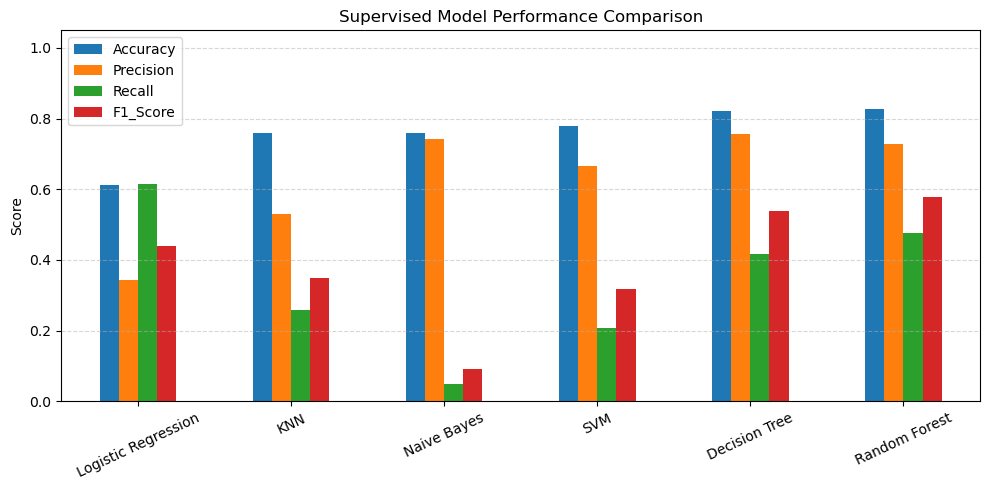

Random Forest Confusion Matrix (Rows=Actual, Cols=Predicted):
[[5456  338]
 [ 996  910]]


In [12]:
# Plot Model Comparison Chart (same chart your dashboard's AI Audit mode will display)
metric_df.plot(kind='bar', figsize=(10, 5))
plt.title('Supervised Model Performance Comparison')
plt.ylabel('Score')
plt.xticks(rotation=25)
plt.ylim(0, 1.05)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

print("Random Forest Confusion Matrix (Rows=Actual, Cols=Predicted):")
print(confusion_matrix(y_test, rf_pred))

## 4. Unsupervised Learning: Anomaly Detection & Clustering
- **Isolation Forest** flags unusual chemical readings (`-1 = Anomaly`, `1 = Normal`) without looking at the `Potability` label.
- **K-Means Clustering** groups water samples into 3 natural water-chemistry profiles to generate the **Cluster Report** required by the problem statement.


In [13]:
from sklearn.ensemble import IsolationForest

iso_forest = IsolationForest(contamination=0.05, random_state=42)
train_anomalies = iso_forest.fit_predict(X_train_new)
test_anomalies = iso_forest.predict(X_test_new)

print("Training Anomalies Found:", int((train_anomalies == -1).sum()))
print("Test Anomalies Found:", int((test_anomalies == -1).sum()))

Training Anomalies Found: 1540
Test Anomalies Found: 395


In [14]:
from sklearn.cluster import KMeans

# Group samples into 3 natural chemical clusters
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
train_clusters = kmeans.fit_predict(X_train_new)
test_clusters = kmeans.predict(X_test_new)

# Build a clean Cluster Report on the test set
cluster_report_df = X_test.copy()
cluster_report_df['Actual_Potability'] = y_test.values
cluster_report_df['Predicted_Potability'] = rf_pred
cluster_report_df['Safety_Score_Pct'] = (rf_prob * 100).round(2)
cluster_report_df['Is_Anomaly'] = test_anomalies
cluster_report_df['Cluster'] = test_clusters

cluster_summary = cluster_report_df.groupby('Cluster').agg(
    Total_Samples=('Predicted_Potability', 'count'),
    Safe_Rate_Pct=('Predicted_Potability', lambda s: round(s.mean() * 100, 2)),
    Anomaly_Rate_Pct=('Is_Anomaly', lambda s: round((s == -1).mean() * 100, 2)),
    Avg_pH=('pH', 'mean'),
    Avg_TDS_mgL=('TDS_mgL', 'mean'),
    Avg_Hardness_mgL=('Hardness_mgL', 'mean'),
    Avg_Turbidity_NTU=('Turbidity_NTU', 'mean')
).round(2)

cluster_summary

,Total_Samples,Safe_Rate_Pct,Anomaly_Rate_Pct,Avg_pH,Avg_TDS_mgL,Avg_Hardness_mgL,Avg_Turbidity_NTU
Cluster,,,,,,,
0,2625,14.06,5.07,6.51,21061.32,198.59,4.23
1,2553,6.15,5.01,7.67,27592.45,187.77,3.61
2,2522,28.63,5.31,7.04,17836.08,203.13,4.15


## 5. Comparing Supervised vs. Unsupervised Results & False Alarm Investigation
Here we split every test sample into **4 operational screening buckets** for Hotel/Campus WTP operators:
1. **Safe & Normal (Green):** Predicted Potable (`1`) and Normal (`1`).
2. **Potential False Alarm (Yellow):** Predicted Potable (`1`) but flagged as Anomaly (`-1`) — unusual but valid measurements that need sensor recheck rather than emergency shutoff.
3. **Confirmed Safety Violation (Red):** Predicted Not Potable (`0`) and Normal (`1`).
4. **Critical Contamination Anomaly (Dark Red):** Predicted Not Potable (`0`) and Anomaly (`-1`).


In [15]:
# Categorize every test sample into the 4 screening buckets
safe_normal = cluster_report_df[
    (cluster_report_df['Predicted_Potability'] == 1) & (cluster_report_df['Is_Anomaly'] == 1)
]
potential_false_alarms = cluster_report_df[
    (cluster_report_df['Predicted_Potability'] == 1) & (cluster_report_df['Is_Anomaly'] == -1)
]
confirmed_violations = cluster_report_df[
    (cluster_report_df['Predicted_Potability'] == 0) & (cluster_report_df['Is_Anomaly'] == 1)
]
critical_anomalies = cluster_report_df[
    (cluster_report_df['Predicted_Potability'] == 0) & (cluster_report_df['Is_Anomaly'] == -1)
]

# Also check training false alarms (bug from original notebook fixed here!)
train_false_alarms_count = int(((train_anomalies == -1) & (y_train.values == 1)).sum())

print("Training False Alarms (Actual Safe + Flagged Anomaly):", train_false_alarms_count)
print("\n--- Test Set Screening Breakdown ---")
print("1. Safe & Normal (Green):               ", len(safe_normal))
print("2. Potential False Alarms (Yellow):     ", len(potential_false_alarms))
print("3. Confirmed Safety Violations (Red):   ", len(confirmed_violations))
print("4. Critical Anomalies (Dark Red):       ", len(critical_anomalies))

Training False Alarms (Actual Safe + Flagged Anomaly): 306

--- Test Set Screening Breakdown ---
1. Safe & Normal (Green):                1216
2. Potential False Alarms (Yellow):      32
3. Confirmed Safety Violations (Red):    6089
4. Critical Anomalies (Dark Red):        363


In [16]:
# Investigate WHY False Alarms happen: compare mean chemical readings across buckets
false_alarm_comparison = pd.DataFrame({
    'Safe_Normal_Mean': safe_normal[numerical_cols].mean(),
    'False_Alarm_Mean': potential_false_alarms[numerical_cols].mean(),
    'Confirmed_Violation_Mean': confirmed_violations[numerical_cols].mean()
}).round(2)

print("Chemical Profile Comparison (Safe vs. False Alarms vs. Violations):")
display(false_alarm_comparison)

print("\nWater Sources causing Potential False Alarms:")
print(potential_false_alarms['Water_Source'].value_counts())

Chemical Profile Comparison (Safe vs. False Alarms vs. Violations):


,Safe_Normal_Mean,False_Alarm_Mean,Confirmed_Violation_Mean
pH,7.41,7.68,6.99
Hardness_mgL,196.61,203.54,196.62
TDS_mgL,16963.37,14593.58,23322.90
Chloramines_mgL,6.37,5.09,7.26
Sulfate_mgL,327.91,314.40,333.97
Conductivity_uScm,424.21,410.88,428.42
Organic_Carbon_mgL,14.23,14.16,14.31
Trihalomethanes_ugL,59.93,56.14,67.29
Turbidity_NTU,3.86,3.74,4.02



Water Sources causing Potential False Alarms:
Water_Source
Reservoir                 14
River_Krishna_Godavari    10
Lake                       7
Borewell                   1
Name: count, dtype: int64


## 6. Influential Chemical Parameters (Global Importance + Local SHAP)
- **Global Importance** shows which chemicals matter most across the entire dataset (used in the dashboard's AI Audit tab).
- **Local SHAP** explains why *one specific hotel or campus sample* passed or failed.


,Water_Features,Impact_Scores
0,pH,0.190209
1,TDS_mgL,0.150599
2,Chloramines_mgL,0.131680
3,Trihalomethanes_ugL,0.102243
4,Turbidity_NTU,0.084787
5,Sulfate_mgL,0.072811
6,Conductivity_uScm,0.068199
7,Organic_Carbon_mgL,0.067658
8,Hardness_mgL,0.067372
9,Water_Source_Borewell,0.007463


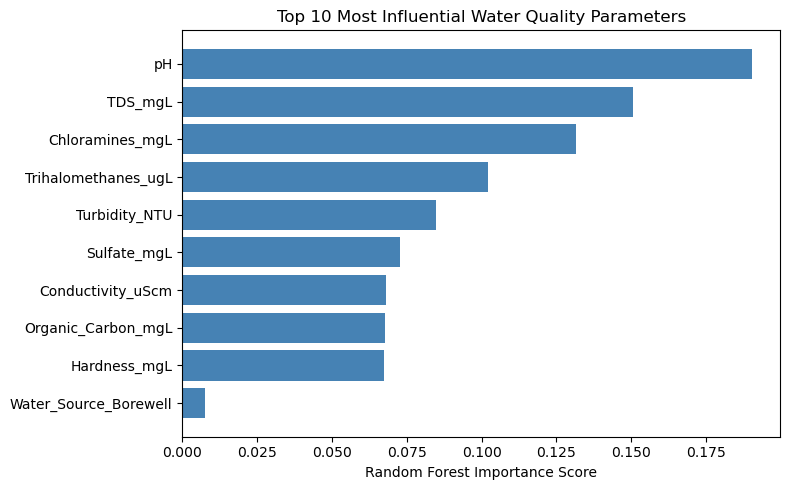

In [17]:
# Global Feature Importances from the best Random Forest
raw_names = preprocessor.get_feature_names_out()
clean_names = []
for name in raw_names:
    clean_names.append(name.replace('num__', '').replace('cat__', ''))

feature_importance = pd.DataFrame({
    'Water_Features': clean_names,
    'Impact_Scores': best_rf.feature_importances_
}).sort_values(by='Impact_Scores', ascending=False).reset_index(drop=True)

top_features = feature_importance.head(12)
display(top_features)

# Plot Top 10 Influential Parameters
plt.figure(figsize=(8, 5))
plt.barh(top_features['Water_Features'][:10][::-1], top_features['Impact_Scores'][:10][::-1], color='steelblue')
plt.title('Top 10 Most Influential Water Quality Parameters')
plt.xlabel('Random Forest Importance Score')
plt.tight_layout()
plt.show()

In [19]:
# Local SHAP Test on 1 Sample (same simple loop used in FastAPI)
%pip install shap
import shap

explainer = shap.TreeExplainer(best_rf)
sample_processed = X_test_new[0:1]

shap_vals = explainer.shap_values(sample_processed)
if isinstance(shap_vals, list):
    class1_shap = shap_vals[1][0]
else:
    class1_shap = shap_vals[0, :, 1]

impact_dict = {}
for i in range(len(clean_names)):
    impact_dict[clean_names[i]] = round(float(class1_shap[i]), 4)

worst_feature = min(impact_dict, key=impact_dict.get)
best_feature = max(impact_dict, key=impact_dict.get)

print("Sample 0 Predicted Potability:", int(best_rf.predict(sample_processed)[0]))
print("Most Negative Driver (toward Unsafe):", worst_feature, impact_dict[worst_feature])
print("Most Positive Driver (toward Safe):  ", best_feature, impact_dict[best_feature])

  Using cached shap-0.54.1-cp312-abi3-win_amd64.whl.metadata (23 kB)
  Using cached slicer-0.0.8-py3-none-any.whl.metadata (4.0 kB)
Using cached shap-0.54.1-cp312-abi3-win_amd64.whl (751 kB)
Using cached slicer-0.0.8-py3-none-any.whl (15 kB)

   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   ---------------------------------------- 2/2 [shap]

Note: you may need to restart the kernel to use updated packages.
Sample 0 Predicted Potability: 0
Most Negative Driver (toward Unsafe): TDS_mgL -0.1226
Most Positive Driver (toward Safe):   Chloramines_mgL 0.0187


## 7. PCA Analysis & Cluster/Anomaly Map
Reduces all processed features into 2 coordinates (`PC1`, `PC2`) so your dashboard can plot normal samples, anomalies, and newly tested hotels/colleges on a 2D scatter plot.


In [20]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
pca_train_data = pca.fit_transform(X_train_new)

print("Explained Variance Ratio (PC1, PC2):", pca.explained_variance_ratio_.round(4))

pca_df = pd.DataFrame(pca_train_data, columns=['PC1', 'PC2'])
pca_df['Potability'] = y_train.values
pca_df['Is_Anomaly'] = train_anomalies
pca_df['Cluster'] = train_clusters
pca_df['District'] = X_train['District'].values
pca_df['Water_Source'] = X_train['Water_Source'].values

# Add human-readable Status label for dashboard colors
status_list = []
for i in range(len(pca_df)):
    pot = pca_df['Potability'].iloc[i]
    anom = pca_df['Is_Anomaly'].iloc[i]
    if pot == 1 and anom == 1:
        status_list.append('Safe & Normal')
    elif pot == 1 and anom == -1:
        status_list.append('Potential False Alarm')
    elif pot == 0 and anom == 1:
        status_list.append('Confirmed Violation')
    else:
        status_list.append('Critical Anomaly')

pca_df['Status'] = status_list
pca_df.head()

Explained Variance Ratio (PC1, PC2): [0.0979 0.097 ]


,PC1,PC2,Potability,Is_Anomaly,Cluster,District,Water_Source,Status
0,-0.637019,-0.592132,0,1,2,Nizamabad,Borewell,Confirmed Violation
1,0.633756,0.982434,0,1,0,Medchal-Malkajgiri,Borewell,Confirmed Violation
2,1.527743,1.654003,0,1,0,Karimnagar,Municipal_Tap,Confirmed Violation
3,1.061476,-0.025349,0,1,1,Hyderabad,Borewell,Confirmed Violation
4,1.665138,-0.179861,0,1,1,Warangal,River_Krishna_Godavari,Confirmed Violation


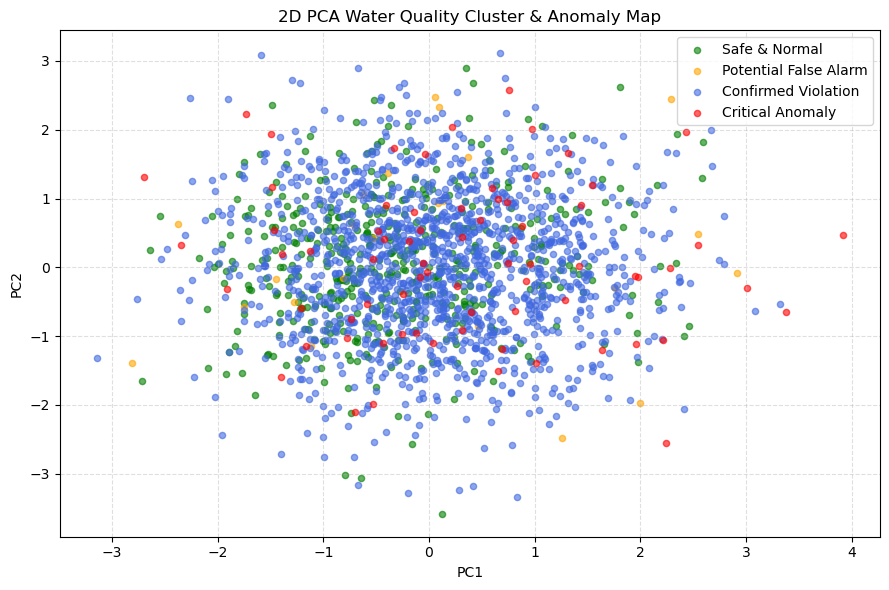

In [21]:
# Visualize a 2,000-point sample of the PCA Anomaly & Potability Map
plot_sample = pca_df.sample(n=2000, random_state=42)

plt.figure(figsize=(9, 6))
color_map = {
    'Safe & Normal': 'green',
    'Potential False Alarm': 'orange',
    'Confirmed Violation': 'royalblue',
    'Critical Anomaly': 'red'
}

for label, color in color_map.items():
    subset = plot_sample[plot_sample['Status'] == label]
    plt.scatter(subset['PC1'], subset['PC2'], c=color, label=label, alpha=0.6, s=20)

plt.title('2D PCA Water Quality Cluster & Anomaly Map')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

## 8. Stakeholder-Ready WTP Helper Functions (Simple Operator Output)
Non-ML operators at Hotels and College/School Campuses need plain-English answers rather than raw ML numbers. These simple functions compute:
1. **Boiler & Plumbing Scaling/Corrosion Risk** (uses `Hardness_mgL`, `TDS_mgL`, `Conductivity_uScm`, `Sulfate_mgL`, `pH`).
2. **Actionable WTP Treatment Steps** (tells maintenance staff which filter or dosing pump to adjust).
3. **Complete Sample Screening & Tap+Borewell Blending Simulator** (exact logic you can reuse inside FastAPI).


In [22]:
# Function 1: Boiler & Pipe Protection Check (Equipment Health for Hotels & Campuses)
def check_boiler_pipe_risk(sample):
    reasons = []

    if sample['pH'] < 6.5:
        reasons.append("Acidic water (pH < 6.5) can corrode metal pipes and boiler heaters.")
    elif sample['pH'] > 8.5:
        reasons.append("High alkalinity (pH > 8.5) accelerates limescale buildup.")

    if sample['Hardness_mgL'] > 220:
        reasons.append("High Hardness (> 220 mg/L): Risk of pipe and water-heater scaling.")

    if sample['TDS_mgL'] > 25000:
        reasons.append("High TDS (> 25,000 mg/L): Heavy load on RO membranes.")

    if sample['Conductivity_uScm'] > 500:
        reasons.append("High Conductivity (> 500 uS/cm): Elevated dissolved salts increase corrosion risk.")

    if sample['Sulfate_mgL'] > 400:
        reasons.append("High Sulfate (> 400 mg/L): Can corrode plumbing and cause bitter taste.")

    if len(reasons) == 0:
        risk_level = "Low"
        reasons.append("Safe for boilers, geysers, and campus plumbing lines.")
    elif len(reasons) == 1:
        risk_level = "Medium"
    else:
        risk_level = "High"

    return {'equipment_risk': risk_level, 'equipment_notes': reasons}


# Function 2: Plain-English WTP Maintenance & Improvement Checklist
def get_treatment_recommendations(sample):
    fixes = []

    if sample['pH'] < 6.5:
        gap = round(6.5 - sample['pH'], 2)
        fixes.append(f"Raise pH by +{gap} using calcite or soda-ash dosing.")
    elif sample['pH'] > 8.5:
        gap = round(sample['pH'] - 8.5, 2)
        fixes.append(f"Lower pH by -{gap} using mild acid dosing before distribution.")

    if sample['TDS_mgL'] > 25000:
        gap = round(sample['TDS_mgL'] - 25000, 1)
        fixes.append(f"Reduce TDS by {gap} mg/L: Backwash or service the RO membrane.")

    if sample['Hardness_mgL'] > 220:
        fixes.append("Regenerate the water softener resin bed to lower Hardness below 220 mg/L.")

    if sample['Chloramines_mgL'] > 8.0:
        fixes.append("Reduce chloramine dosing or pass water through Activated Carbon (GAC) filter.")

    if sample['Trihalomethanes_ugL'] > 80.0 or sample['Organic_Carbon_mgL'] > 18.0:
        fixes.append("High organics/disinfection byproducts: Replace Activated Carbon (GAC) media.")

    if sample['Turbidity_NTU'] > 5.0:
        fixes.append("High cloudiness (Turbidity > 5 NTU): Run sand/multimedia filtration and sedimentation.")

    if sample['Sulfate_mgL'] > 400.0:
        fixes.append("High Sulfate (> 400 mg/L): Route through RO or ion-exchange unit.")

    if len(fixes) == 0:
        fixes.append("No corrective maintenance needed. Continue routine WTP monitoring.")

    return fixes


# Function 3: All-in-One Screening Function (Ready for FastAPI)
def screen_water_sample(sample):
    input_df = pd.DataFrame([sample])
    processed = preprocessor.transform(input_df)

    prediction = int(best_rf.predict(processed)[0])
    safety_score = round(float(best_rf.predict_proba(processed)[0][1]) * 100, 2)
    anomaly = int(iso_forest.predict(processed)[0])
    cluster_id = int(kmeans.predict(processed)[0])
    coords = pca.transform(processed)[0]

    if prediction == 1 and anomaly == 1:
        color = "GREEN"
        status = "Safe to Supply"
    elif prediction == 1 and anomaly == -1:
        color = "YELLOW"
        status = "Recheck Sensor (Potential False Alarm)"
    elif prediction == 0 and anomaly == 1:
        color = "RED"
        status = "Hold Supply (Confirmed Safety Violation)"
    else:
        color = "DARK RED"
        status = "Emergency Shutoff (Critical Contamination Anomaly)"

    equipment = check_boiler_pipe_risk(sample)
    fixes = get_treatment_recommendations(sample)

    return {
        'Color_Code': color,
        'Operator_Status': status,
        'Potability': prediction,
        'Drinking_Safety_Pct': safety_score,
        'Is_Anomaly': anomaly,
        'Cluster_ID': cluster_id,
        'PC1': round(float(coords[0]), 4),
        'PC2': round(float(coords[1]), 4),
        'Boiler_Pipe_Risk': equipment['equipment_risk'],
        'Equipment_Notes': equipment['equipment_notes'],
        'Treatment_Fixes': fixes
    }

In [23]:
# Test the Stakeholder Screening Function on 3 Realistic Hyderabad Hotel/Campus Samples

# 1. Clean Hotel Municipal Tap
hotel_tap = {
    'District': 'Hyderabad', 'Water_Source': 'Municipal_Tap',
    'pH': 7.2, 'Hardness_mgL': 190.0, 'TDS_mgL': 16500.0,
    'Chloramines_mgL': 6.2, 'Sulfate_mgL': 305.0, 'Conductivity_uScm': 410.0,
    'Organic_Carbon_mgL': 13.5, 'Trihalomethanes_ugL': 55.0, 'Turbidity_NTU': 3.4
}

# 2. Contaminated Campus Borewell
campus_borewell = {
    'District': 'Hyderabad', 'Water_Source': 'Borewell',
    'pH': 5.4, 'Hardness_mgL': 265.0, 'TDS_mgL': 33000.0,
    'Chloramines_mgL': 9.8, 'Sulfate_mgL': 435.0, 'Conductivity_uScm': 590.0,
    'Organic_Carbon_mgL': 19.2, 'Trihalomethanes_ugL': 92.0, 'Turbidity_NTU': 5.8
}

print("--- 1. Hotel Municipal Tap ---")
print(json.dumps(screen_water_sample(hotel_tap), indent=2))

print("\n--- 2. Campus Borewell ---")
print(json.dumps(screen_water_sample(campus_borewell), indent=2))

--- 1. Hotel Municipal Tap ---
{
  "Color_Code": "GREEN",
  "Operator_Status": "Safe to Supply",
  "Potability": 1,
  "Drinking_Safety_Pct": 81.9,
  "Is_Anomaly": 1,
  "Cluster_ID": 2,
  "PC1": -0.5994,
  "PC2": -0.219,
  "Boiler_Pipe_Risk": "Low",
  "Equipment_Notes": [
    "Safe for boilers, geysers, and campus plumbing lines."
  ],
  "Treatment_Fixes": [
    "No corrective maintenance needed. Continue routine WTP monitoring."
  ]
}

--- 2. Campus Borewell ---
{
  "Color_Code": "DARK RED",
  "Operator_Status": "Emergency Shutoff (Critical Contamination Anomaly)",
  "Potability": 0,
  "Drinking_Safety_Pct": 25.11,
  "Is_Anomaly": -1,
  "Cluster_ID": 0,
  "PC1": 1.5242,
  "PC2": 2.149,
  "Boiler_Pipe_Risk": "High",
  "Equipment_Notes": [
    "Acidic water (pH < 6.5) can corrode metal pipes and boiler heaters.",
    "High Hardness (> 220 mg/L): Risk of pipe and water-heater scaling.",
    "High TDS (> 25,000 mg/L): Heavy load on RO membranes.",
    "High Conductivity (> 500 uS/cm): Elev

In [24]:
# Test the Tap + Borewell Blending Calculator (e.g., 70% Municipal Tap + 30% Borewell)
def blend_two_sources(source_a, source_b, ratio_a=0.7):
    ratio_b = 1.0 - ratio_a
    blended = {
        'District': source_a['District'],
        'Water_Source': source_a['Water_Source']
    }
    for col in numerical_cols:
        blended[col] = round(source_a[col] * ratio_a + source_b[col] * ratio_b, 2)
    return screen_water_sample(blended)

print("--- Blended Result (75% Hotel Tap + 25% Campus Borewell) ---")
print(json.dumps(blend_two_sources(hotel_tap, campus_borewell, ratio_a=0.75), indent=2))

--- Blended Result (75% Hotel Tap + 25% Campus Borewell) ---
{
  "Color_Code": "GREEN",
  "Operator_Status": "Safe to Supply",
  "Potability": 1,
  "Drinking_Safety_Pct": 86.7,
  "Is_Anomaly": 1,
  "Cluster_ID": 0,
  "PC1": -0.0675,
  "PC2": 0.3744,
  "Boiler_Pipe_Risk": "Low",
  "Equipment_Notes": [
    "Safe for boilers, geysers, and campus plumbing lines."
  ],
  "Treatment_Fixes": [
    "No corrective maintenance needed. Continue routine WTP monitoring."
  ]
}


## 9. Export All Models & Dashboard Data Files for FastAPI
Notice we save `best_rf` directly into `rf_model.pkl` (much smaller and faster to load in FastAPI and SHAP than saving the full `rf_grid` search wrapper).


In [25]:
# 1. Save trained ML models & transformers
joblib.dump(best_rf, 'rf_model.pkl')
joblib.dump(iso_forest, 'iso_forest.pkl')
joblib.dump(kmeans, 'kmeans_model.pkl')
joblib.dump(preprocessor, 'preprocessor.pkl')
joblib.dump(pca, 'pca.pkl')

# 2. Save Model Performance JSON (for dashboard's Model Comparison chart)
with open('model_performance.json', 'w') as f:
    json.dump(results, f, indent=2)

# 3. Save Global Feature Importance JSON (for dashboard's Influential Parameters chart)
importance_list = []
for i in range(len(top_features)):
    importance_list.append({
        'feature': top_features['Water_Features'].iloc[i],
        'importance': round(float(top_features['Impact_Scores'].iloc[i]), 5)
    })

with open('feature_importance.json', 'w') as f:
    json.dump(importance_list, f, indent=2)

# 4. Save lightweight 2,000-row PCA sample for smooth browser scatter plots
pca_export = pca_df.sample(n=2000, random_state=42)
pca_export.to_csv('pca_dashboard_data.csv', index=False)

print("All files exported successfully:")
print("- rf_model.pkl")
print("- iso_forest.pkl")
print("- kmeans_model.pkl")
print("- preprocessor.pkl")
print("- pca.pkl")
print("- model_performance.json")
print("- feature_importance.json")
print("- pca_dashboard_data.csv")

All files exported successfully:
- rf_model.pkl
- iso_forest.pkl
- kmeans_model.pkl
- preprocessor.pkl
- pca.pkl
- model_performance.json
- feature_importance.json
- pca_dashboard_data.csv
